# O que falta fazer?

- [X] Avaliação quantitativa: medir se as recomendações são boas; separar algumas avaliações e ver se o algoritmo consegue recuperar os livros que o usuário gostou.

- Avaliação qualitativa: medir se as recomendações são boas; usar https://www.goodreads.com/ para comparar com nosso algoritmo para ver se as recomendações são boas.

- [X] Investigar a importância de ajustar o `k` para ver se o algoritmo muda muito, k = 5, 10, 20, 50, etc.

- [X] Mostrar a proporção de avaliações existentes em relação a todas as combinações possíveis de usuários e livros, e discutir como isso afeta a busca de vizinhos.

- Comparar as estratégias de forma que responda: quando usar uma ou outra? Além de mostrar as duas listas de livros, investigar em quais condições cada estratégia funciona melhor e quanto as recomendações se sobrepõem.

# O que usar?

- Recall, precision, F1-score
- [X] Mostrar como a recomendação foi construida (usar `.neighbors` e `.similar_books` de cada classe de estratégia)
- Em novos valores de K, plotar como a precision, recall de F1 alteram com bae no K

# Explorar

- [X] Os dados do dataset são bem esparsos, como isso impacta? como filtrar bons dados? o `elegible_users` faz algo assim, mas é insuficiente.
- Nota zero e ausência de avaliação não são necessariamente a mesma coisa. Como trabalhar com cada um?
- Evidenciar que precisamos de avaliações para rodar o algoritmo, não tem conceito de "gosto" aqui, pois isso é muito implícito nas avaliações. Usuários com poucas avaliações tem muita perda? como o algoritmo se comporta?

# Aprendizado de Máquina

## Sistemas de recomendação

- Fábio Felsky
- Lemuel Manske
- Thiago Russi

Dataset: https://www.kaggle.com/datasets/arashnic/book-recommendation-dataset

## Objetivo

Desenvolver um algoritmo de recomendação para recomendar livros para usuários.

Entrada: usuário (ID), saída: livros recomendados.

## Entidades

**Livros**: ISBN, ano de publicação, título e autor.

**Usuários**: ID, localidade.

**Avaliações**: usuário *x*  livro.

## Clarificações

- 0 significa feedback implícito: usuário interagiu com o livro mas não deu uma nota

- 1-10 significa feedback explícito

## Desafios

> Como o algoritmo consegue descobrir que dois livros estão relacionados se não sabemos seus gêneros, assuntos ou sinopses?

## Estratégias

> O que o algoritmo deve procurar primeiro para fazer uma recomendação?

| Usuário | Livro A | Livro B | Livro C | Livro D |
|---|---|---|---|---|
| João | 10 | 2 | — | — |
| Maria | 10 | 2 | 10 | 2 |
| Ana | 9 | 7 | 2 | 9 |
| Pedro | 8 | 8 | 2 | 8 |
| Luiza | 7 | 9 | 2 | 9 |

### Filtragem baseada em livros (afinidade por item)

Procura livros parecidos entre si.

> João gostou do livro A mas não do B. Quais outros livros apresentam padrões de avaliação semelhantes aos de A?

**Recomendação:** Livro D, pois seu padrão de avaliações apresenta afinidade com o Livro A, de que João gostou.

### Filtragem baseada em usuários (afinidade por usuário)

Procura usuários parecidos entre si.

> João gostou do livro A mas não do B. Quais usuários possuem gostos parecidos com os dele? E quais outros livros essas pessoas gostaram?

**Recomendação:** Livro C, pois Maria possui avaliações idênticas às de João nos livros A e B e gostou do Livro C.

## Parte 1: Importar dataset e criar `DataFrames`

In [ ]:
import kagglehub

from pathlib import Path

path = Path(kagglehub.dataset_download("arashnic/book-recommendation-dataset"))

BOOKS_PATH = path / "Books.csv"
RATINGS_PATH = path / "Ratings.csv"
USERS_PATH = path / "Users.csv"

Using Colab cache for faster access to the 'book-recommendation-dataset' dataset.


In [ ]:
import csv

import pandas as pd

books = []
ratings = []
users = []

with open(BOOKS_PATH, newline='') as f:
  r = csv.reader(f, delimiter=',')
  books = list(r)

with open(RATINGS_PATH, newline='') as f:
  r = csv.reader(f, delimiter=',')
  ratings = list(r)

with open(USERS_PATH, newline='') as f:
  r = csv.reader(f, delimiter=',')
  users = list(r)

books_df = pd.DataFrame(books[1:], columns=books[0])
ratings_df = pd.DataFrame(ratings[1:], columns=ratings[0])
users_df = pd.DataFrame(users[1:], columns=users[0])

In [ ]:
ratings_df.head()

,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0
3,276729,052165615X,3
4,276729,0521795028,6


## Parte 2: Organizar dataset

In [ ]:
ratings_df["Book-Rating"] = pd.to_numeric(
    ratings_df["Book-Rating"],
    errors="coerce"
)

# Extrair ratings explícitos (0 = implícito)
explicit_ratings = ratings_df[ratings_df["Book-Rating"] > 0]

## Parte 2.1: Entender dataset

,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0
3,276729,052165615X,3
4,276729,0521795028,6


,Book-Rating
count,1.149780e+06
mean,2.866950e+00
std,3.854184e+00
min,0.000000e+00
25%,0.000000e+00
50%,0.000000e+00
75%,7.000000e+00
max,1.000000e+01


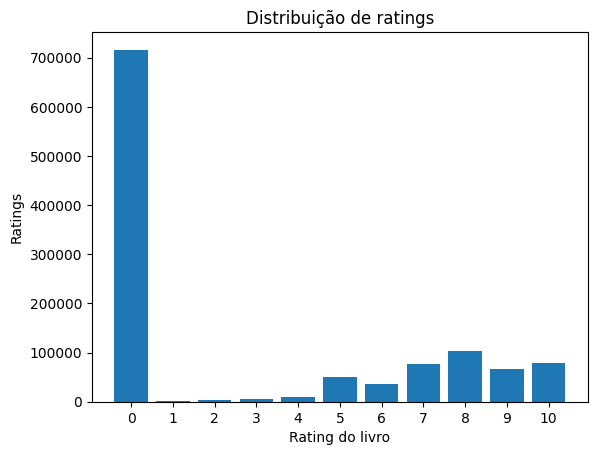

In [ ]:
print()
display(ratings_df.head())

print()
display(ratings_df.describe())


import matplotlib.pyplot as plt

print()

user_x_ratings_counts = ratings_df["Book-Rating"].value_counts().sort_index()

plt.bar(user_x_ratings_counts.index, user_x_ratings_counts.values)

plt.xlabel("Rating do livro")
plt.ylabel("Ratings")
plt.title("Distribuição de ratings")
plt.xticks(range(0, int(ratings_df["Book-Rating"].max()) + 1))
plt.show()

Podemos ver que a distribuição é irregular:
- Existem muitos feedbacks implícitos
- O restante é melhor distribuído, mas feedbacks ruins são poucos

In [ ]:
# Aqui definimos alguns utilitários

_, user_ids = pd.factorize(ratings_df["User-ID"])
_, book_isbns = pd.factorize(ratings_df["ISBN"])

# Map user => rating (total)
user_x_ratings = explicit_ratings \
  .groupby("User-ID") \
  .size() \
  .sort_values(ascending=False)

# Map book => rating (total)
book_x_ratings = ratings_df.groupby("ISBN") \
  .size() \
  .sort_values(ascending=False)

# Map user-id => idx
user_to_idx = {
    str(user_id): idx
    for idx, user_id in enumerate(user_ids)
}

# Map ISBN => title
books_by_isbn = books_df \
  .drop_duplicates(subset="ISBN") \
  .set_index("ISBN")["Book-Title"] \
  .to_dict()

# ISBNs
book_isbns = [
    book_isbn
    for book_isbn in book_isbns
]

def user_details(user_id):
    user_id = str(user_id)

    if user_id not in user_to_idx.keys():
        return {
            "ID": user_id,
            "Localidade": "Desconhecida",
        }

    user_idx = user_to_idx[user_id]
    user = users_df.iloc[user_idx]

    return {
        "ID": user_id,
        "Localidade": user["Location"],
    }

def book_details(isbn):
    isbn = str(isbn)

    if isbn not in book_info.index:
        return {
            "ISBN": isbn,
            "Título": "Desconhecido",
            "Autor": "Desconhecido",
        }

    book = book_info.loc[isbn]

    return {
        "ISBN": isbn,
        "Título": book["Book-Title"],
        "Autor": book["Book-Author"],
    }

In [ ]:
print()
display(user_x_ratings.head())

print()
display(book_x_ratings.head())

,0
User-ID,
11676,8524
98391,5802
153662,1969
189835,1906
23902,1395


,0
ISBN,
0971880107,2502
0316666343,1295
0385504209,883
0060928336,732
0312195516,723


Existem ISBNs únicos para a mesma obra? Quer dizer, uma mesma obra pode possuir múltiplos IDs? Isso é importante, pois, para o algoritmo, deveria ser ISBN 1:1 Obra.

In [ ]:
book_groups = (
    books_df[["ISBN", "Book-Title", "Book-Author"]]
    .drop_duplicates("ISBN")
)

book_groups["work_id"] = (
    book_groups["Book-Title"].str.strip().str.casefold()
    + " | "
    + book_groups["Book-Author"].str.strip().str.casefold()
)

ratings_with_works = explicit_ratings.merge(
    book_groups[["ISBN", "work_id"]],
    on="ISBN",
    how="inner"
)

ratings_per_work = (
    ratings_with_works.groupby("work_id")
    .agg(
        ratings=("Book-Rating", "size"),
        editions=("ISBN", "nunique"),
    )
)

print(
    "Avaliações pertencentes a obras com múltiplos ISBNs:",
    f"{ratings_per_work.loc[ratings_per_work['editions'] > 1, 'ratings'].sum() / len(ratings_with_works):.2%}"
)

Avaliações pertencentes a obras com múltiplos ISBNs: 31.58%



Top 10 raters:


,0
User-ID,
11676,8524
98391,5802
153662,1969
189835,1906
23902,1395
76499,1036
171118,1035
235105,1023
16795,968



Mode: 1
Median: 1.0



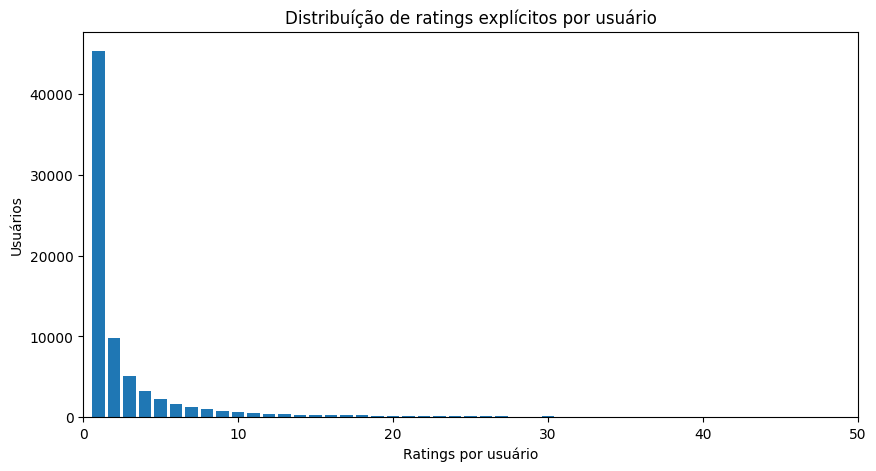

In [ ]:
print()
print('Top 10 raters:')

top_10_raters = user_x_ratings.head(10)
display(top_10_raters)

print()

mode = user_x_ratings.mode()
print(f'Mode: {mode[0]}')

median = user_x_ratings.median()
print(f'Median: {median}')


import matplotlib.pyplot as plt

print()

user_x_ratings_counts = user_x_ratings \
  .value_counts() \
  .sort_index()

plt.figure(figsize=(10, 5))
plt.bar(user_x_ratings_counts.index, user_x_ratings_counts.values)

plt.xlim(0, 50)
plt.xlabel("Ratings por usuário")
plt.ylabel("Usuários")
plt.title("Distribuíção de ratings explícitos por usuário")
plt.show()

Podemos concluir que a grande maioria dos usuários só avaliou um único livro. Isso, teoricamente, é ruim para o propósito do trabalho, pois o sistema se baseia exclusivamente nos ratings, quer dizer, uma única avaliação é muito pouco para deduzir as preferências do usuário, impactando na qualidade da recomendação. Mais para frente vamos explorar isso mais a fundo.

Com isso, precisamos visualizar qual a distribuição de ratings por livro além dos usuários para chegar numa conclusão mais apropriada.

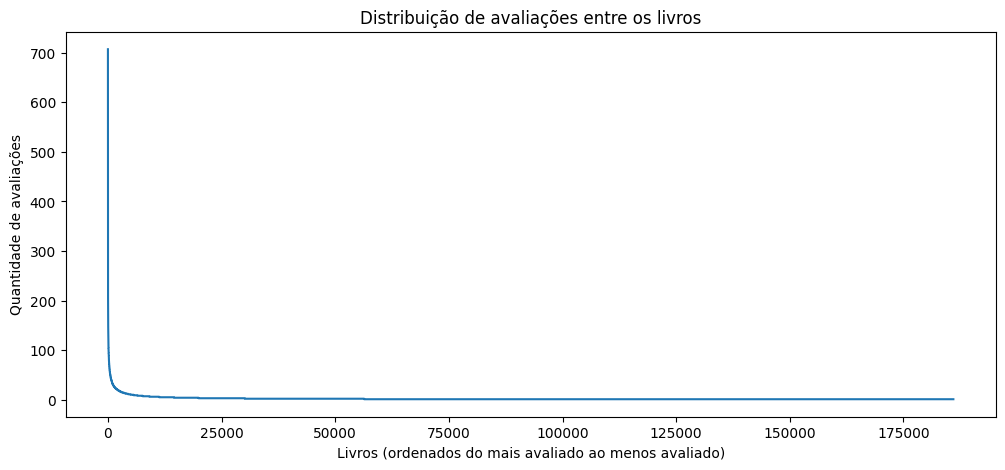

In [ ]:
import matplotlib.pyplot as plt

book_counts = (
    explicit_ratings.groupby("ISBN")
    .size()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 5))

plt.plot(range(1, len(book_counts) + 1), book_counts.values)

plt.xlabel("Livros (ordenados do mais avaliado ao menos avaliado)")
plt.ylabel("Quantidade de avaliações")
plt.title("Distribuição de avaliações entre os livros")
plt.show()

Agora sabemos que as avaliações também estão concentradas em poucos títulos.

Para filtragem baseada em usuário, isso gera dois cenários:

- Usuários que avaliaram livros populares: têm maior probabilidade de encontrar outros usuários que avaliaram os mesmos livros. Entretanto, compartilhar apenas uma avaliação não é suficiente para estimar **similaridade com confiança**.
- Usuários que avaliaram livros pouco populares: têm menor probabilidade de encontrar outros usuários com avaliações em comum, dificultando a identificação de vizinhos.

Para filtragem baseada em livros, a consequência é mais direta: livros populares tendem a ter estimativas de similaridade mais bem fundamentadas, enquanto livros pouco avaliados podem ficar praticamente isolados, ou seja, não serem recomendados.

In [ ]:
import pandas as pd
import numpy as np

from scipy.sparse import csr_matrix

def build_matrices(df):
  global M, T, user_to_idx, book_isbns, user_ids
  global M_ones, T_ones

  user_codes, user_ids = pd.factorize(df["User-ID"])
  book_codes, book_isbns = pd.factorize(df["ISBN"])

  M = csr_matrix(
    (
      df["Book-Rating"].to_numpy(dtype=float),
      (user_codes, book_codes)
    ),
    shape=(len(user_ids), len(book_isbns))
  )

  T = M.T.tocsr()

  M_ones = M.copy()
  M_ones.data[:] = 1

  T_ones = M_ones.T.tocsr()

  user_to_idx = {
    str(user_id): idx
    for idx, user_id in enumerate(user_ids)
  }


build_matrices(explicit_ratings)

In [ ]:
print(M.shape) # Usuários, ISBNs
print(T.shape) # ISBNs, Usuários

(77805, 185973)
(185973, 77805)


In [ ]:
preview = pd.DataFrame(
    M[:10, :10].toarray(),
    index=user_ids[:10],
    columns=book_isbns[:10]
)

print()
print('Matriz normal:')

display(preview.replace(0, float("nan")))

preview_T = pd.DataFrame(
    T[:10, :10].toarray(),
    index=book_isbns[:10],
    columns=user_ids[:10]
)

print()
print('Matriz transposta:')

display(preview_T.replace(0, float("nan")))


Matriz normal:


,0155061224,052165615X,0521795028,3257224281,0600570967,038550120X,342310538,0060517794,0671537458,0679776818
276726,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
276729,NaN,3.0,6.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
276736,NaN,NaN,NaN,8.0,NaN,NaN,NaN,NaN,NaN,NaN
276737,NaN,NaN,NaN,NaN,6.0,NaN,NaN,NaN,NaN,NaN
276744,NaN,NaN,NaN,NaN,NaN,7.0,NaN,NaN,NaN,NaN
276745,NaN,NaN,NaN,NaN,NaN,NaN,10.0,NaN,NaN,NaN
276747,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.0,9.0,8.0
276748,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
276751,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
276754,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Matriz transposta:


,276726,276729,276736,276737,276744,276745,276747,276748,276751,276754
0155061224,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
052165615X,NaN,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0521795028,NaN,6.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3257224281,NaN,NaN,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0600570967,NaN,NaN,NaN,6.0,NaN,NaN,NaN,NaN,NaN,NaN
038550120X,NaN,NaN,NaN,NaN,7.0,NaN,NaN,NaN,NaN,NaN
342310538,NaN,NaN,NaN,NaN,NaN,10.0,NaN,NaN,NaN,NaN
0060517794,NaN,NaN,NaN,NaN,NaN,NaN,9.0,NaN,NaN,NaN
0671537458,NaN,NaN,NaN,NaN,NaN,NaN,9.0,NaN,NaN,NaN
0679776818,NaN,NaN,NaN,NaN,NaN,NaN,8.0,NaN,NaN,NaN


Até agora, os resultados demonstraram ser pouco favoráveis ao kNN, pois a esparsidade dos dados pode ser bastante prejudicial. Mas, como podemos provar isso?

Logo abaixo, calculamos a cobertura de potencial vizinhos, tanto para usuários como para livros.

In [ ]:
def max_overlap(matrix, batch_size=256):
  maximums = np.zeros(matrix.shape[0], dtype=np.int32)

  for start in range(0, matrix.shape[0], batch_size):
    end = min(start + batch_size, matrix.shape[0])

    overlap = matrix[start:end] @ matrix.T

    # Ignorar a comparação de cada entidade consigo mesma
    overlap = overlap.tolil()

    for local_idx, global_idx in enumerate(range(start, end)):
      overlap[local_idx, global_idx] = 0

    overlap = overlap.tocsr()
    overlap.eliminate_zeros()

    for local_idx in range(end - start):
      row = overlap.getrow(local_idx)

      if row.nnz:
        maximums[start + local_idx] = row.data.max()

  return maximums

In [ ]:
user_max_overlap = max_overlap(M_ones)
book_max_overlap = max_overlap(T_ones)

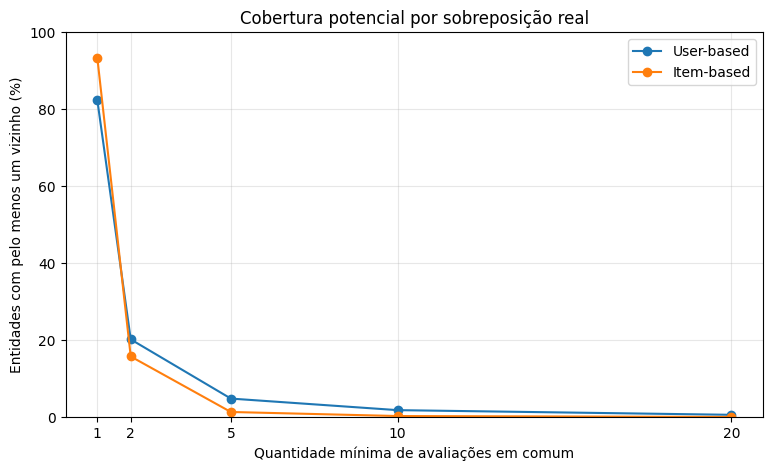

In [ ]:
KERNELS = [1, 2, 5, 10, 20]

results = pd.DataFrame({
    "Min. overlap": KERNELS,
    "Usuários (%)": [
        100 * np.mean(user_max_overlap >= k)
        for k in KERNELS
    ],
    "Livros (%)": [
        100 * np.mean(book_max_overlap >= k)
        for k in KERNELS
    ]
})


import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    results["Min. overlap"],
    results["Usuários (%)"],
    marker="o",
    label="User-based"
)

plt.plot(
    results["Min. overlap"],
    results["Livros (%)"],
    marker="o",
    label="Item-based"
)

plt.xlabel("Quantidade mínima de avaliações em comum")
plt.ylabel("Entidades com pelo menos um vizinho (%)")
plt.title("Cobertura potencial por sobreposição real")
plt.xticks(KERNELS)
plt.ylim(0, 100)
plt.legend()
plt.grid(alpha=0.3)

plt.show()

A análise da sobreposição entre avaliações revelou que, embora exista uma conectividade relativamente elevada entre usuários e livros, essa conectividade é sustentada predominantemente por relações de baixa sobreposição. A maioria das entidades possui ao menos um vizinho potencial, mas poucas apresentam vizinhos com múltiplas avaliações compartilhadas. Essa característica limita a confiabilidade das estimativas de similaridade utilizadas pelos algoritmos de filtragem colaborativa baseados em kNN.

Embora isso seja interpretado como ruim para o propósito do trabalho, podemos ver o outro lado: como explorar os limites do kNN? Como podemos garantir boas recomendações embora tudo isso? É possível?

## Parte 3: Preparando algoritmos

In [ ]:
import numpy as np

from sklearn.neighbors import NearestNeighbors

# Essa é a principal função do projeto
# Ela que seleciona os vizinhos, e possui vários hiperparâmetros para testarmos possibilidades
def select_neighbors(
    model,
    matrix,
    binary_matrix,
    index,
    k=20,
    candidate_pool=100, # Quantos candidatos pré-selecionar. Proporcional com o custo computacional
    min_overlap=1, # Mínimo de avaliações em comum
    shrinkage=0.0, # Quanto penalizar uma similaridade muito otimista
    metric="cosine",
    exclude=None,
):
  assert metric in {"cosine", "euclidean"}
  assert k > 0

  exclude = set() if exclude is None else set(exclude)
  exclude.add(index) # Não recomendar o próprio candidato

  # Buscar candidatos antes de aplicar os filtros
  n_candidates = min(
    max(k, candidate_pool) + len(exclude),
    matrix.shape[0],
  )

  dists, idxs = model.kneighbors(
    matrix.getrow(index),
    n_neighbors=n_candidates,
  )

  source = binary_matrix.getrow(index)
  neighbors = []

  for idx, dist in zip(idxs[0], dists[0]):
    idx = int(idx)

    if idx in exclude:
      continue

    # Converter distância para similaridade, respeitando se for cos. ou euclid.
    if metric == "cosine":
      similarity = max(0.0, 1.0 - float(dist))
    elif metric == "euclidean":
      similarity = 1.0 / (1.0 + float(dist))

    if similarity <= 0:
      continue

    # Quantidade de avaliações compartilhadas
    target = binary_matrix.getrow(idx)

    overlap = np.intersect1d(
      source.indices,
      target.indices,
      assume_unique=True,
    ).size

    if overlap < min_overlap:
      continue

    # Penalizar relações com pouca sobreposição (muito otimistas), pois muito provavelmente é uma recomendação precipitada
    if shrinkage > 0:
      similarity *= overlap / (overlap + shrinkage)

    neighbors.append((idx, similarity))

  # Reordenar após a regularização
  neighbors.sort(key=lambda item: item[1], reverse=True)

  return neighbors[:k]

### O que é `min_overlap`?

Esse parâmetro define a quantidade mínima de avaliações em comum para considerar vizinhos.

| Usuário |	Livro A |	Livro B |	Livro C |
| --- | --- | --- | --- |
| Alice |	9 |	8 |	— |
| Bob |	8 |	7 |	10 |
| Carlos |	9 |	— |	6 |

Para filtragem baseada em usuários, por exemplo:

- Alice x Bob: `overlap` = 2 (livros A e B).
- Alice x Carlos: `overlap` = 1 (livro A).

Para filtragem baseeada em livros:

- Livro A x Livro B: `overlap` = 2 (Alice e Bob).

###  O que é `shrinkage`?

Imagine:

| Neighbor | Similarity | Livros em comum |
| --- | --- | --- |
| Alice | .95 | 1 |
| Bob | .88 | 20 |

Aqui, embora Bob tenha uma similaridade mais baixa, é muito mais provável que a recomendação que parte de Bob seja mais segura que de Alice para um usuário X.

Quanto maior a sobreposição, maior tende a ser a confiança que podemos depositar na estimativa de similaridade. Mas isso não significa necessariamente que a chance de acertar a recomendação seja muito maior.

In [ ]:
from sklearn.neighbors import NearestNeighbors

from collections import defaultdict
from dataclasses import dataclass, field
from typing import Protocol


@dataclass
class Recommendation:
  isbn: str
  score: float


@dataclass
class FilterResult:
  user_id: str
  recommendations: list[Recommendation]
  candidates: set[str] = field(default_factory=set)


class Filter(Protocol):
  def recommend(self, user_id: str, n: int) -> FilterResult:
    ...


@dataclass
class UserBasedFilterResult(FilterResult):
  neighbors: list[tuple[str, float]] = field(default_factory=list)


@dataclass
class BookBasedFilterResult(FilterResult):
  similar_books: dict[str, list[tuple[str, float]]] = field(
    default_factory=dict
  )

from collections import defaultdict


class UserBasedFilter(Filter):
  def __init__(
    self,
    metric="cosine",
    algorithm="brute",
    k=20,
    candidate_pool=100,
    min_overlap=1,
    shrinkage=0.0,
  ):
    self.metric = metric
    self.k = k
    self.candidate_pool = candidate_pool
    self.min_overlap = min_overlap
    self.shrinkage = shrinkage

    self.M = M.tocsr()
    self.M_ones = M_ones.tocsr()

    self.model = NearestNeighbors(
      metric=metric,
      algorithm=algorithm,
    )
    self.model.fit(self.M)

  def recommend(self, user_id: str, n: int) -> UserBasedFilterResult:
    user_idx = user_to_idx[user_id]

    user_ratings = self.M.getrow(user_idx)
    rated_books = set(user_ratings.indices)

    neighbors = select_neighbors(
      model=self.model,
      matrix=self.M,
      binary_matrix=self.M_ones,
      index=user_idx,
      k=self.k,
      candidate_pool=self.candidate_pool,
      min_overlap=self.min_overlap,
      shrinkage=self.shrinkage,
      metric=self.metric,
    )

    scores = defaultdict(float)
    weights = defaultdict(float)

    for idx, similarity in neighbors:
      neighbor_ratings = self.M.getrow(idx)

      for book_idx, rating in zip(
        neighbor_ratings.indices,
        neighbor_ratings.data,
      ):
        book_idx = int(book_idx)

        if book_idx in rated_books:
          continue

        scores[book_idx] += similarity * (float(rating) / 10)
        weights[book_idx] += similarity

    ranking = sorted(
      scores,
      key=scores.get,
      reverse=True,
    )

    recommendations = []

    for idx in ranking:
      isbn = str(book_isbns[idx])

      if books_by_isbn.get(isbn) is None:
        continue

      recommendations.append(
        Recommendation(
          isbn=isbn,
          score=float(scores[idx]),
        )
      )

      if len(recommendations) >= n:
        break

    candidates = {
      str(book_isbns[idx])
      for idx in scores
    }

    return UserBasedFilterResult(
      user_id=user_id,
      recommendations=recommendations,
      candidates=candidates,
      neighbors=[
        (str(user_ids[idx]), float(similarity))
        for idx, similarity in neighbors
        ],
    )


class BookBasedFilter(Filter):
  def __init__(
    self,
    metric="cosine",
    algorithm="brute",
    k=20,
    min_rating=7,
    candidate_pool=100,
    min_overlap=1,
    shrinkage=0.0,
  ):
    self.metric = metric
    self.k = k
    self.min_rating = min_rating
    self.candidate_pool = candidate_pool
    self.min_overlap = min_overlap
    self.shrinkage = shrinkage

    self.M = M.tocsr()
    self.MT = T.tocsr()
    self.T_ones = T_ones.tocsr()

    self.model = NearestNeighbors(
      metric=metric,
      algorithm=algorithm,
    )
    self.model.fit(self.MT)

  def recommend(self, user_id: str, n: int) -> BookBasedFilterResult:
    user_idx = user_to_idx[user_id]

    user_ratings = self.M.getrow(user_idx)
    rated_books = set(user_ratings.indices)

    liked_books = [
      (int(idx), float(rating))
      for idx, rating in zip(
        user_ratings.indices,
        user_ratings.data,
      )
      if rating >= self.min_rating
    ]

    scores = defaultdict(float)
    weights = defaultdict(float)
    contributions = defaultdict(list)

    for book_idx, rating in liked_books:
      neighbors = select_neighbors(
        model=self.model,
        matrix=self.MT,
        binary_matrix=self.T_ones,
        index=book_idx,
        k=self.k,
        candidate_pool=self.candidate_pool,
        min_overlap=self.min_overlap,
        shrinkage=self.shrinkage,
        metric=self.metric,
        exclude=rated_books,
      )

      for idx, similarity in neighbors:
        scores[idx] += similarity * (rating / 10)
        weights[idx] += similarity

        contributions[idx].append(
          (str(book_isbns[book_idx]), similarity)
        )

    ranking = sorted(
      scores,
      key=scores.get,
      reverse=True,
    )

    recommendations = []
    similar_books = {}

    for idx in ranking:
      isbn = str(book_isbns[idx])

      if books_by_isbn.get(isbn) is None:
        continue

      recommendations.append(
        Recommendation(
          isbn=isbn,
          score=float(scores[idx]),
        )
      )

      similar_books[isbn] = sorted(
        contributions[idx],
        key=lambda item: item[1],
        reverse=True,
      )

      if len(recommendations) >= n:
        break

    candidates = {
      str(book_isbns[idx])
      for idx in scores
    }

    return BookBasedFilterResult(
      user_id=user_id,
      recommendations=recommendations,
      candidates=candidates,
      similar_books=similar_books,
    )

## Parte 4.1: Análise quantitativa

In [ ]:
import numpy as np
import pandas as pd

def split_ratings(min_positive_rating: int = 7):
  df = explicit_ratings.copy().reset_index(drop=True)

  df["User-ID"] = df["User-ID"].astype(str)
  df["ISBN"] = df["ISBN"].astype(str)

  user_counts = df.groupby("User-ID").size()

  positive = df[df["Book-Rating"] >= min_positive_rating]
  positive_counts = positive.groupby("User-ID").size()

  eligible = user_counts.index[
    (user_counts >= 3)
    & (positive_counts.reindex(user_counts.index, fill_value=0) >= 2)
  ]

  rng = np.random.default_rng(42) # Fixar a seed para não tornar isso um bias

  validation_idx = []
  test_idx = []

  for _, group in positive[
    positive["User-ID"].isin(eligible)
  ].groupby("User-ID"):

    selected = rng.choice(
      group.index.to_numpy(),
      size=2,
      replace=False
    )

    validation_idx.append(int(selected[0]))
    test_idx.append(int(selected[1]))

  validation = df.loc[validation_idx].copy()
  test = df.loc[test_idx].copy()

  train = df.drop(
    index=validation_idx + test_idx
  ).copy()

  return train, validation, test

In [ ]:
def evaluate(model: Filter, test: pd.DataFrame, n: int = 10):
  results = []

  for user_id, isbn in zip(test["User-ID"], test["ISBN"]):
    user_id, isbn = str(user_id), str(isbn)

    result = model.recommend(user_id, n)
    recommendations = [rec.isbn for rec in result.recommendations]

    rank = recommendations.index(isbn) + 1 if isbn in recommendations else None

    results.append({
      "user_id": user_id,
      "isbn": isbn,
      "candidate_hit": isbn in result.candidates,
      "ranking_hit": rank is not None,
      "candidate_count": len(result.candidates),
      "recommendation_count": len(recommendations),
      "ndcg": 1 / np.log2(rank + 1) if rank is not None else 0.0,
    })

  details = pd.DataFrame(results)

  hit_rate = details["ranking_hit"].mean()

  metrics = {
    "CandidateRecall": float(details["candidate_hit"].mean()),
    f"HitRate@{n}": float(hit_rate),
    f"NDCG@{n}": float(details["ndcg"].mean()),
    f"Precision@{n}": float(hit_rate / n),
    "Coverage": float((details["recommendation_count"] > 0).mean()),
    "AvgCandidates": float(details["candidate_count"].mean()),
  }

  return metrics, details

In [ ]:
from sklearn.model_selection import ParameterGrid

def grid_search(filter_class, validation, param_grid, n=10, **fixed_params):
  results = []

  for params in ParameterGrid(param_grid):
    model = filter_class(
      metric="cosine",
      algorithm="brute",
      **fixed_params,
      **params,
    )

    metrics, _ = evaluate(model, validation, n=n)

    results.append({
      "model": filter_class.__name__,
      **fixed_params,
      **params,
      **metrics,
    })

  return (
    pd.DataFrame(results)
    .sort_values(
      [f"NDCG@{n}", f"HitRate@{n}"],
      ascending=False,
    )
    .reset_index(drop=True)
  )

In [ ]:
PARAM_GRID = {
    "k": [20, 50, 100],
    "candidate_pool": [100, 300, 500],
    "min_overlap": [1, 2, 5],
    "shrinkage": [0.0, 5.0],
}

train_df, validation_df, test_df = split_ratings()

build_matrices(train_df)

validation_sample = validation_df.sample(
    n=min(100, len(validation_df)),
    random_state=42,
)

user_results = grid_search(
    UserBasedFilter,
    validation_sample,
    PARAM_GRID,
)

book_results = grid_search(
    BookBasedFilter,
    validation_sample,
    PARAM_GRID,
    min_rating=5,
)

display(user_results.head(10))
display(book_results.head(10))

,model,candidate_pool,k,min_overlap,shrinkage,CandidateRecall,HitRate@10,NDCG@10,Precision@10,Coverage,AvgCandidates
0,UserBasedFilter,300,100,1,5.0,0.18,0.05,0.042619,0.005,0.87,3492.21
1,UserBasedFilter,500,100,1,5.0,0.18,0.05,0.042619,0.005,0.87,3552.41
2,UserBasedFilter,300,50,1,5.0,0.13,0.05,0.038928,0.005,0.86,2328.12
3,UserBasedFilter,500,50,1,5.0,0.13,0.05,0.038928,0.005,0.86,2371.06
4,UserBasedFilter,100,100,1,0.0,0.15,0.04,0.036309,0.004,0.85,3351.97
5,UserBasedFilter,100,100,1,5.0,0.15,0.04,0.036309,0.004,0.85,3351.97
6,UserBasedFilter,300,100,1,0.0,0.15,0.04,0.036309,0.004,0.85,3351.96
7,UserBasedFilter,500,100,1,0.0,0.15,0.04,0.036309,0.004,0.85,3351.97
8,UserBasedFilter,100,50,1,5.0,0.11,0.04,0.032619,0.004,0.82,2288.18
9,UserBasedFilter,100,50,1,0.0,0.11,0.04,0.028928,0.004,0.80,2196.67


,model,min_rating,candidate_pool,k,min_overlap,shrinkage,CandidateRecall,HitRate@10,NDCG@10,Precision@10,Coverage,AvgCandidates
0,BookBasedFilter,5,300,20,1,5.0,0.07,0.06,0.038175,0.006,0.86,156.65
1,BookBasedFilter,5,300,20,2,5.0,0.07,0.06,0.038175,0.006,0.80,54.45
2,BookBasedFilter,5,300,50,1,5.0,0.07,0.06,0.038175,0.006,0.86,371.58
3,BookBasedFilter,5,300,50,2,5.0,0.07,0.06,0.038175,0.006,0.80,83.42
4,BookBasedFilter,5,300,100,1,5.0,0.08,0.06,0.038175,0.006,0.86,693.65
5,BookBasedFilter,5,300,100,2,5.0,0.07,0.06,0.038175,0.006,0.80,100.34
6,BookBasedFilter,5,500,20,1,5.0,0.07,0.06,0.037482,0.006,0.86,156.79
7,BookBasedFilter,5,500,20,2,5.0,0.07,0.06,0.037482,0.006,0.80,62.48
8,BookBasedFilter,5,500,50,1,5.0,0.07,0.06,0.037482,0.006,0.86,371.12
9,BookBasedFilter,5,500,50,2,5.0,0.07,0.06,0.037482,0.006,0.80,96.88


User-based
Menor HitRate: 0.00%
Maior HitRate: 5.00%
HitRate médio: 1.80%
Amplitude: 5.00%

Item-based
Menor HitRate: 2.00%
Maior HitRate: 6.00%
HitRate médio: 4.63%
Amplitude: 4.00%



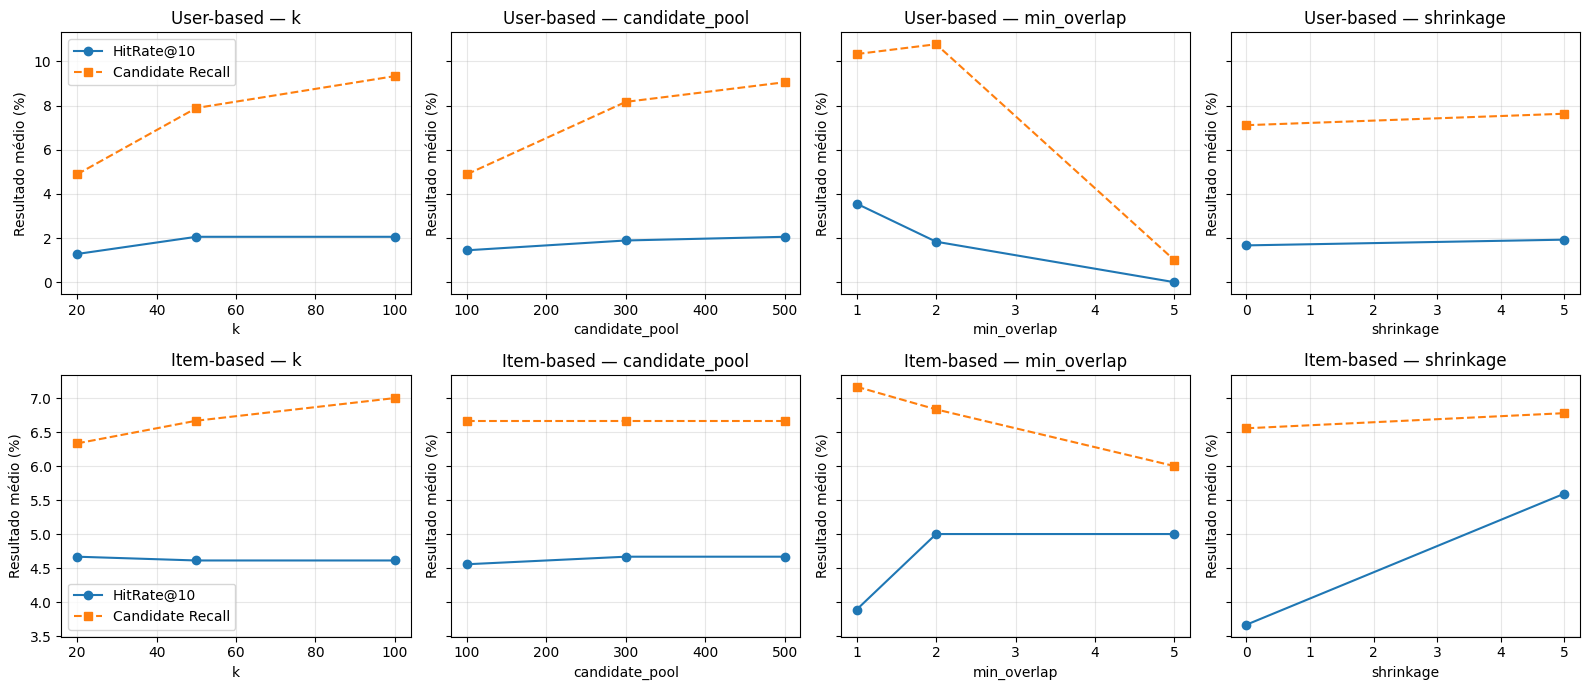

In [ ]:
import matplotlib.pyplot as plt

params = ["k", "candidate_pool", "min_overlap", "shrinkage"]

fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey="row")

for row, (name, results) in enumerate([
  ("User-based", user_results),
  ("Item-based", book_results),
]):
  for col, param in enumerate(params):
    ax = axes[row, col]

    grouped = results.groupby(param)[
      ["HitRate@10", "CandidateRecall"]
    ].mean() * 100

    ax.plot(
      grouped.index,
      grouped["HitRate@10"],
      "o-",
      label="HitRate@10",
    )

    ax.plot(
      grouped.index,
      grouped["CandidateRecall"],
      "s--",
      label="Candidate Recall",
    )

    ax.set_title(f"{name} — {param}")
    ax.set_xlabel(param)
    ax.set_ylabel("Resultado médio (%)")
    ax.grid(alpha=0.3)

    if col == 0:
      ax.legend()

for name, results in [
  ("User-based", user_results),
  ("Item-based", book_results),
]:
  hit = results["HitRate@10"]

  print(name)
  print(f"Menor HitRate: {hit.min():.2%}")
  print(f"Maior HitRate: {hit.max():.2%}")
  print(f"HitRate médio: {hit.mean():.2%}")
  print(f"Amplitude: {(hit.max() - hit.min()):.2%}")
  print()

plt.tight_layout()
plt.show()

In [ ]:
user_best = user_results.iloc[0]
book_best = book_results.iloc[0]

def best_params(row):
  return {
    "k": int(row["k"]),
    "candidate_pool": int(row["candidate_pool"]),
    "min_overlap": int(row["min_overlap"]),
    "shrinkage": float(row["shrinkage"]),
  }

display(user_best)
display(book_best)

user_model = UserBasedFilter(
  **best_params(user_best),
  aggregation="sum",
)

book_model = BookBasedFilter(
  **best_params(book_best),
  min_rating=5,
  aggregation="sum",
)

,0
model,UserBasedFilter
candidate_pool,300
k,100
min_overlap,1
shrinkage,5.0
CandidateRecall,0.18
HitRate@10,0.05
NDCG@10,0.042619
Precision@10,0.005
Coverage,0.87


,0
model,BookBasedFilter
min_rating,5
candidate_pool,300
k,20
min_overlap,1
shrinkage,5.0
CandidateRecall,0.07
HitRate@10,0.06
NDCG@10,0.038175
Precision@10,0.006


TypeError: UserBasedFilter.__init__() got an unexpected keyword argument 'aggregation'

In [ ]:
user_metrics, user_details = evaluate(
    user_model, validation_df, n=10
)

book_metrics, book_details = evaluate(
    book_model, validation_df, n=10
)

summary = pd.DataFrame({
    "User-based": user_metrics,
    "Item-based": book_metrics,
}).T

display(summary.round(4))

In [ ]:
metrics = ["CandidateRecall", "HitRate@10"]

ax = (summary[metrics] * 100).plot.bar(
    figsize=(8, 4),
    rot=0,
)

ax.set_title("Desempenho dos melhores modelos kNN")
ax.set_ylabel("Recuperação (%)")
ax.legend(["Candidate Recall", "HitRate@10"])
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## A limitação da popularidade

In [ ]:
book_counts = train_df.groupby("ISBN").size()

bins = [-1, 0, 2, 9, 49, float("inf")]
labels = ["0", "1–2", "3–9", "10–49", "50+"]

def by_popularity(details):
  df = details.copy()

  df["popularity"] = (
    df["isbn"].map(book_counts).fillna(0)
  )

  df["group"] = pd.cut(
    df["popularity"],
    bins=bins,
    labels=labels,
  )

  return df.groupby("group", observed=False).agg(
    users=("isbn", "size"),
    candidate_recall=("candidate_hit", "mean"),
    hit_rate=("ranking_hit", "mean"),
  )

_, user_details = evaluate(
  UserBasedFilter(k=100),
  test_df,
  n=10,
)

user_popularity = by_popularity(user_details)
book_popularity = by_popularity(book_details)

display(user_popularity)
display(book_popularity)

AttributeError: 'function' object has no attribute 'copy'

## Onde o kNN consegue recuperar livros?

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))

x = np.arange(len(labels))
width = 0.35

ax.bar(
  x - width / 2,
  user_popularity["hit_rate"] * 100,
  width,
  label="User-based",
)

ax.bar(
  x + width / 2,
  book_popularity["hit_rate"] * 100,
  width,
  label="Item-based",
)

ax.set_xticks(x, labels)
ax.set_xlabel("Avaliações do livro no treinamento")
ax.set_ylabel("HitRate@10 (%)")
ax.set_title("Recuperação por popularidade — melhores modelos")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## Parte 4.2: Análise qualitativa

In [ ]:
import requests

from PIL import Image
from io import BytesIO
from functools import lru_cache

@lru_cache(maxsize=100)
def load_book_cover(isbn):
  url = f"https://covers.openlibrary.org/b/isbn/{isbn}-M.jpg?default=false"

  try:
    response = requests.get(url, timeout=5)
    response.raise_for_status()

    image = Image.open(BytesIO(response.content))
    return image.convert("RGB")
  except Exception:
    return None